<a href="https://colab.research.google.com/github/yunus-emr7denizhan/Data-Science-Machine-Learning-Bootcamp/blob/main/2_Hafta_Veri_Bilimi/ETicaret_Is_Zekasi/HSD_TRAI_Bootcamp_Final_Odevi_Is_Zekasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**HAZIRLIK; Gerekli Kütüphanelerin kurulumu ve ayarlama, Veri yükleme**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Görselleştirme Ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# Temizlenmiş veriyi yüklüyoruz
df = pd.read_csv('e_ticaret_veri_seti_aykiri_degerler_duzenlendi - Kopya.csv')
df['siparis_tarihi'] = pd.to_datetime(df['siparis_tarihi']) # Zaman serisi analizi için

## Soru 1: Hangi kategori hem ticari performans hem de müşteri memnuniyeti açısından en güçlü görünüyor?

,kategori,Siparis_Sayisi,Toplam_Gelir,Ort_Siparis_Tutari,Ort_Musteri_Puani,Ort_Teslimat_Gunu
0,Elektronik,140,212930.29,1520.930643,4.235714,3.321429
1,Ev Yaşam,184,142335.55,773.562772,4.260870,3.445652
2,Kitap,223,114075.59,511.549731,4.251121,3.417040
3,Kozmetik,200,147522.90,737.614500,4.420000,3.350000
4,Ofis,162,47051.88,290.443704,4.240741,3.129630
5,Spor,186,189481.91,1018.719946,4.263441,3.182796


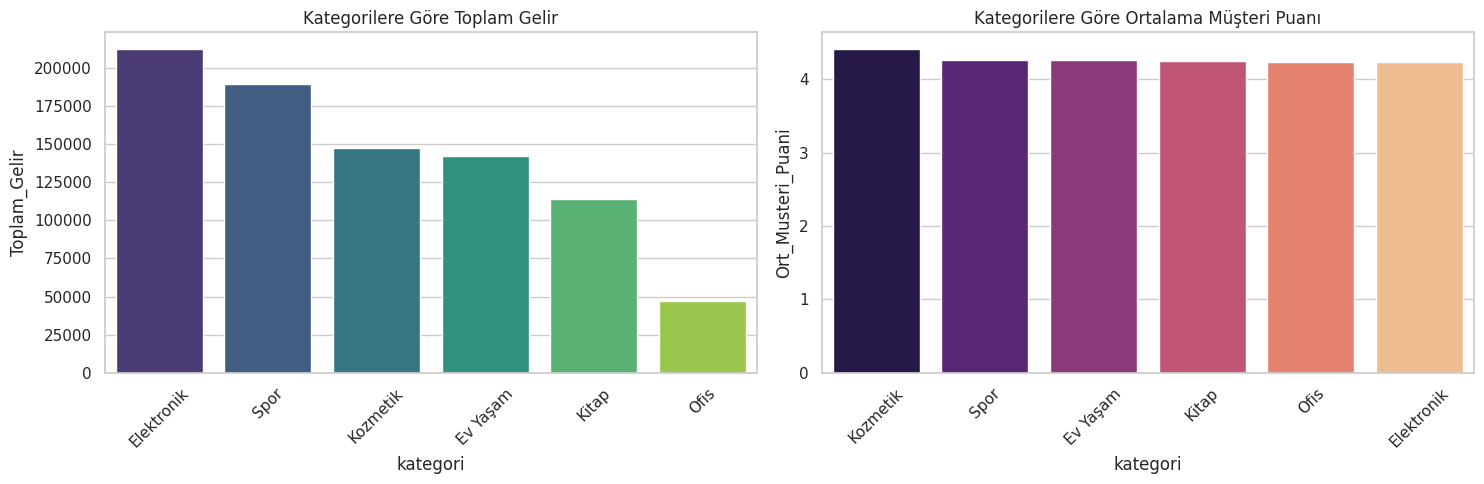



 🎯 İŞ YORUMU: Toplam gelir açısından en güçlü kategori 'Elektronik' iken, müşteri memnuniyeti açısından en yüksek kategori 'Kozmetik' olmuştur.
 Ticari performansı maksimize etmek için 'Elektronik' kategorisinde müşteri deneyimini (hızlı teslimat vb.) artıracak iyileştirmeler yapılmalıdır.


In [3]:
# Özet Tablo
cat_df = df.groupby('kategori').agg(
    Siparis_Sayisi=('siparis_id', 'count'),
    Toplam_Gelir=('toplam_tutar', 'sum'),
    Ort_Siparis_Tutari=('toplam_tutar', 'mean'),
    Ort_Musteri_Puani=('musteri_puani', 'mean'),
    Ort_Teslimat_Gunu=('teslimat_gunu', 'mean')
).reset_index()
display(cat_df)

# Grafikler
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=cat_df.sort_values('Toplam_Gelir', ascending=False), x='kategori', y='Toplam_Gelir', ax=axes[0], palette='viridis', hue='kategori')
axes[0].set_title('Kategorilere Göre Toplam Gelir')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(data=cat_df.sort_values('Ort_Musteri_Puani', ascending=False), x='kategori', y='Ort_Musteri_Puani', ax=axes[1], palette='magma', hue='kategori')
axes[1].set_title('Kategorilere Göre Ortalama Müşteri Puanı')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# İş Yorumu
best_rev_cat = cat_df.sort_values('Toplam_Gelir', ascending=False).iloc[0]['kategori']
best_score_cat = cat_df.sort_values('Ort_Musteri_Puani', ascending=False).iloc[0]['kategori']
print(f"\n\n 🎯 İŞ YORUMU: Toplam gelir açısından en güçlü kategori '{best_rev_cat}' iken, müşteri memnuniyeti açısından en yüksek kategori '{best_score_cat}' olmuştur.\n Ticari performansı maksimize etmek için '{best_rev_cat}' kategorisinde müşteri deneyimini (hızlı teslimat vb.) artıracak iyileştirmeler yapılmalıdır.")

## Soru 2: Hangi şehirler daha yüksek potansiyel taşıyor?

,sehir,Siparis_Sayisi,Toplam_Gelir,Ort_Siparis_Tutari,Ort_Musteri_Puani
12,İstanbul,264,224020.57,848.562765,4.356061
1,Ankara,124,96721.13,780.009113,4.185484
13,İzmir,118,88718.51,751.851780,4.177966
2,Antalya,86,63712.80,740.846512,4.279070
8,Konya,77,59424.33,771.744545,4.363636
0,Adana,63,50353.28,799.258413,4.333333
3,Bursa,67,46782.83,698.251194,4.208955
9,Mersin,46,38043.87,827.040652,4.217391
4,Eskişehir,45,37550.04,834.445333,4.244444
10,Samsun,45,36263.46,805.854667,4.444444


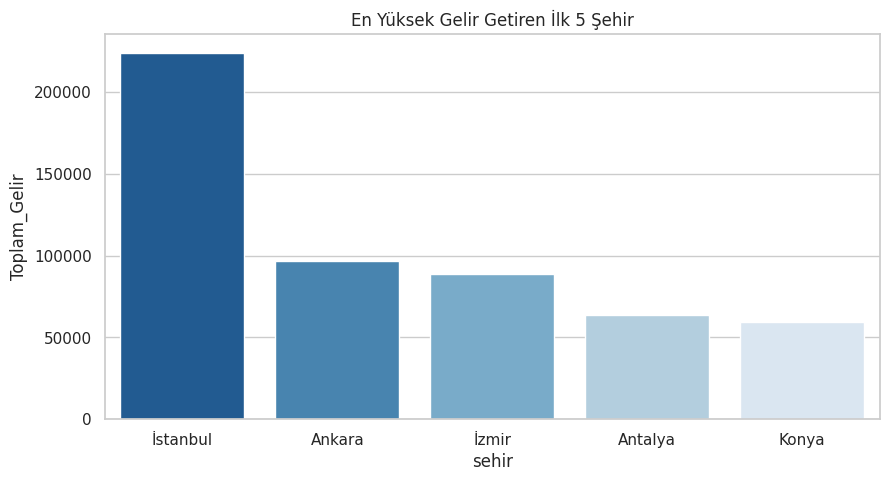



 🎯 İŞ YORUMU: Gelirde zirve çeken ilk 5 şehir grafikte görülmektedir. Ancak müşteri memnuniyeti Türkiye ortalamasının üzerinde olup geliri düşük kalan şehirler (Konya, Adana, Samsun vb.) 
 ciddi bir büyüme potansiyeli taşımaktadır. Bu illere hedeflenmiş pazarlama kampanyaları düzenlenmelidir.


In [9]:
# Özet Tablo
city_df = df.groupby('sehir').agg(
    Siparis_Sayisi=('siparis_id', 'count'),
    Toplam_Gelir=('toplam_tutar', 'sum'),
    Ort_Siparis_Tutari=('toplam_tutar', 'mean'),
    Ort_Musteri_Puani=('musteri_puani', 'mean')
).reset_index().sort_values('Toplam_Gelir', ascending=False)
display(city_df.head(10))

# Grafik
plt.figure(figsize=(10, 5))
sns.barplot(data=city_df.head(5), x='sehir', y='Toplam_Gelir', palette='Blues_r', hue='sehir')
plt.title('En Yüksek Gelir Getiren İlk 5 Şehir')
plt.show()

# İş Yorumu
mean_score = city_df['Ort_Musteri_Puani'].mean()
mean_rev = city_df['Toplam_Gelir'].mean()
growth_cities = city_df[(city_df['Ort_Musteri_Puani'] > mean_score) & (city_df['Toplam_Gelir'] < mean_rev)]['sehir'].tolist()
print(f"\n\n 🎯 İŞ YORUMU: Gelirde zirve çeken ilk 5 şehir grafikte görülmektedir. Ancak müşteri memnuniyeti Türkiye ortalamasının üzerinde olup geliri düşük kalan şehirler ({', '.join(growth_cities[:3])} vb.) \n ciddi bir büyüme potansiyeli taşımaktadır. Bu illere hedeflenmiş pazarlama kampanyaları düzenlenmelidir.")

## Soru 3: Hangi ödeme türü daha değerli müşteri davranışı üretiyor?

,odeme_turu,Siparis_Sayisi,Toplam_Gelir,Ort_Siparis_Tutari,Ort_Musteri_Puani,Ort_Teslimat_Gunu
0,Banka Kartı,169,143011.08,846.219408,4.236686,3.526627
1,Dijital Cüzdan,153,129911.25,849.093137,4.267974,3.267974
2,Havale/EFT,111,92894.46,836.887027,4.153153,3.135135
3,Kapıda Ödeme,79,48113.17,609.027468,4.379747,3.240506
4,Kredi Kartı,583,439468.16,753.804734,4.310463,3.310463


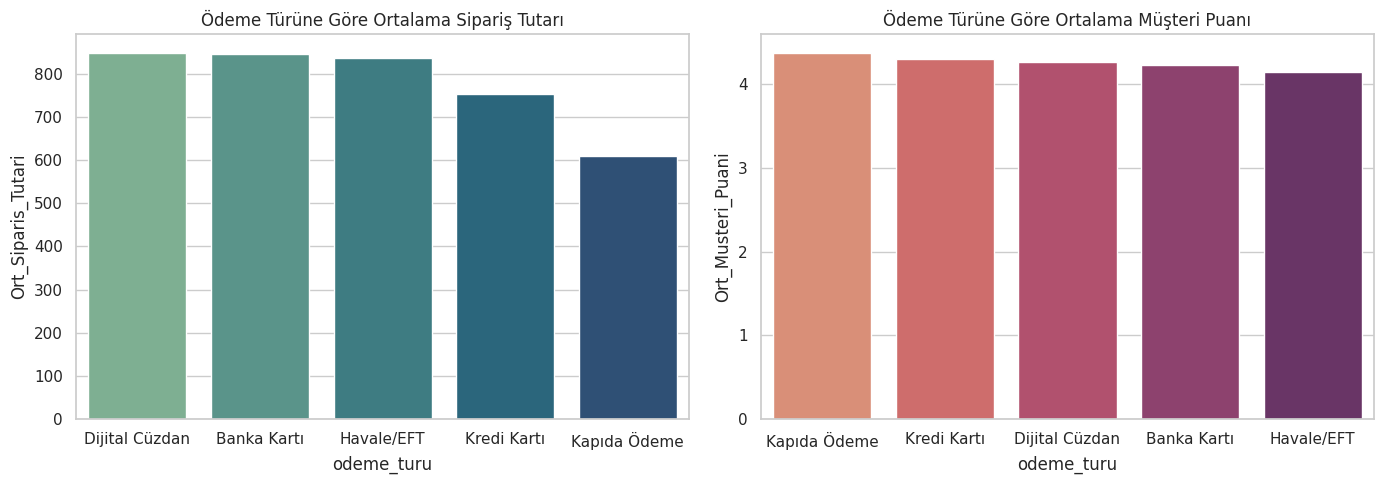


 🎯 İŞ YORUMU: Sepet tutarını en çok artıran değerli ödeme yöntemi 'Dijital Cüzdan' olarak öne çıkmaktadır. En yüksek müşteri memnuniyeti ise 'Kapıda Ödeme' ile sağlanmaktadır.
 Ortalama sipariş tutarını artırmak için müşterileri 'Dijital Cüzdan' kullanımına teşvik edecek özel avantajlar sunulabilir.


In [10]:
# Özet Tablo
pay_df = df.groupby('odeme_turu').agg(
    Siparis_Sayisi=('siparis_id', 'count'),
    Toplam_Gelir=('toplam_tutar', 'sum'),
    Ort_Siparis_Tutari=('toplam_tutar', 'mean'),
    Ort_Musteri_Puani=('musteri_puani', 'mean'),
    Ort_Teslimat_Gunu=('teslimat_gunu', 'mean')
).reset_index()
display(pay_df)

# Grafikler
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=pay_df.sort_values('Ort_Siparis_Tutari', ascending=False), x='odeme_turu', y='Ort_Siparis_Tutari', ax=axes[0], palette='crest', hue='odeme_turu')
axes[0].set_title('Ödeme Türüne Göre Ortalama Sipariş Tutarı')

sns.barplot(data=pay_df.sort_values('Ort_Musteri_Puani', ascending=False), x='odeme_turu', y='Ort_Musteri_Puani', ax=axes[1], palette='flare', hue='odeme_turu')
axes[1].set_title('Ödeme Türüne Göre Ortalama Müşteri Puanı')
plt.tight_layout()
plt.show()

# İş Yorumu
best_rev_pay = pay_df.sort_values('Ort_Siparis_Tutari', ascending=False).iloc[0]['odeme_turu']
best_score_pay = pay_df.sort_values('Ort_Musteri_Puani', ascending=False).iloc[0]['odeme_turu']
print(f"\n 🎯 İŞ YORUMU: Sepet tutarını en çok artıran değerli ödeme yöntemi '{best_rev_pay}' olarak öne çıkmaktadır. En yüksek müşteri memnuniyeti ise '{best_score_pay}' ile sağlanmaktadır.\n Ortalama sipariş tutarını artırmak için müşterileri '{best_rev_pay}' kullanımına teşvik edecek özel avantajlar sunulabilir.")

## Soru 4: Zaman içinde satış davranışı nasıl değişiyor?

,Ay_Yil,Siparis_Sayisi,Toplam_Gelir,Ort_Siparis_Tutari
0,2024-01,46,34042.04,740.044348
1,2024-02,44,38718.64,879.969091
2,2024-03,49,39860.81,813.485918
3,2024-04,58,32489.79,560.168793
4,2024-05,40,32971.89,824.297250
5,2024-06,48,41530.49,865.218542
6,2024-07,37,29977.82,810.211351
7,2024-08,39,27338.81,700.995128
8,2024-09,45,34076.18,757.248444
9,2024-10,41,34290.06,836.342927


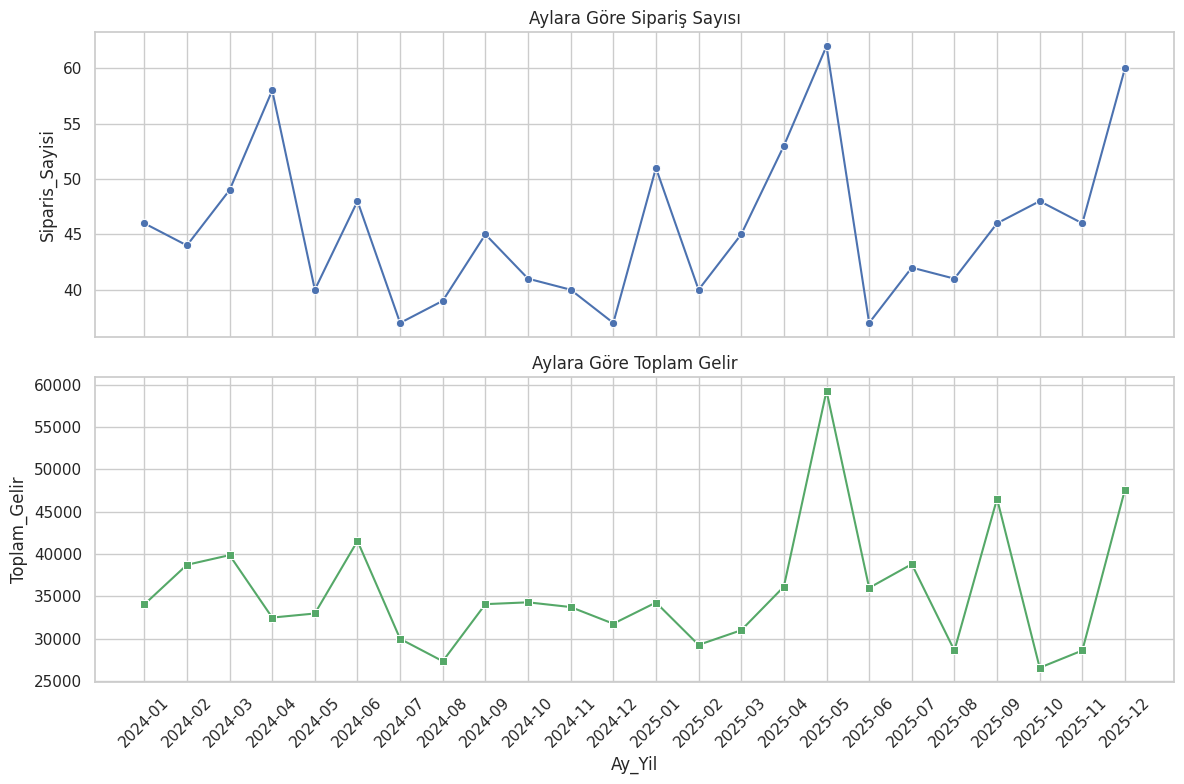


🎯 İŞ YORUMU: En yoğun sipariş alınan ay 2025-05 iken, en yüksek gelir elde edilen ay 2025-05 olmuştur.
 Sipariş hacmi ile gelir artışı arasındaki paralellik veya sapmalar, o dönemde yapılan indirim kampanyalarının karlılığa etkisini doğrudan göstermektedir.


In [12]:
# Özet Tablo
df['Ay_Yil'] = df['siparis_tarihi'].dt.to_period('M').astype(str)
month_df = df.groupby('Ay_Yil').agg(
    Siparis_Sayisi=('siparis_id', 'count'),
    Toplam_Gelir=('toplam_tutar', 'sum'),
    Ort_Siparis_Tutari=('toplam_tutar', 'mean')
).reset_index().sort_values('Ay_Yil')
display(month_df)

# Grafikler
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
sns.lineplot(data=month_df, x='Ay_Yil', y='Siparis_Sayisi', ax=axes[0], marker='o', color='b')
axes[0].set_title('Aylara Göre Sipariş Sayısı')

sns.lineplot(data=month_df, x='Ay_Yil', y='Toplam_Gelir', ax=axes[1], marker='s', color='g')
axes[1].set_title('Aylara Göre Toplam Gelir')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# İş Yorumu
peak_orders = month_df.sort_values('Siparis_Sayisi', ascending=False).iloc[0]['Ay_Yil']
peak_rev = month_df.sort_values('Toplam_Gelir', ascending=False).iloc[0]['Ay_Yil']
print(f"\n🎯 İŞ YORUMU: En yoğun sipariş alınan ay {peak_orders} iken, en yüksek gelir elde edilen ay {peak_rev} olmuştur.\n Sipariş hacmi ile gelir artışı arasındaki paralellik veya sapmalar, o dönemde yapılan indirim kampanyalarının karlılığa etkisini doğrudan göstermektedir.")

## Soru 5: Hangi şehir-kategori kombinasyonları en güçlü fırsatı sunuyor?

,sehir,kategori,Siparis_Sayisi,Toplam_Gelir,Ort_Siparis_Tutari,Ort_Musteri_Puani,Sehir_Kategori
72,İstanbul,Elektronik,45,66731.92,1482.931556,4.177778,İstanbul - Elektronik
77,İstanbul,Spor,43,53391.34,1241.659070,4.325581,İstanbul - Spor
73,İstanbul,Ev Yaşam,43,34130.59,793.734651,4.418605,İstanbul - Ev Yaşam
75,İstanbul,Kozmetik,42,33167.28,789.697143,4.547619,İstanbul - Kozmetik
74,İstanbul,Kitap,56,27106.12,484.037857,4.285714,İstanbul - Kitap
83,İzmir,Spor,26,25196.08,969.080000,4.153846,İzmir - Spor
6,Ankara,Elektronik,15,23401.32,1560.088000,4.133333,Ankara - Elektronik
11,Ankara,Spor,23,22817.79,992.077826,4.347826,Ankara - Spor
48,Konya,Elektronik,15,22342.84,1489.522667,4.400000,Konya - Elektronik
78,İzmir,Elektronik,14,18487.02,1320.501429,4.214286,İzmir - Elektronik


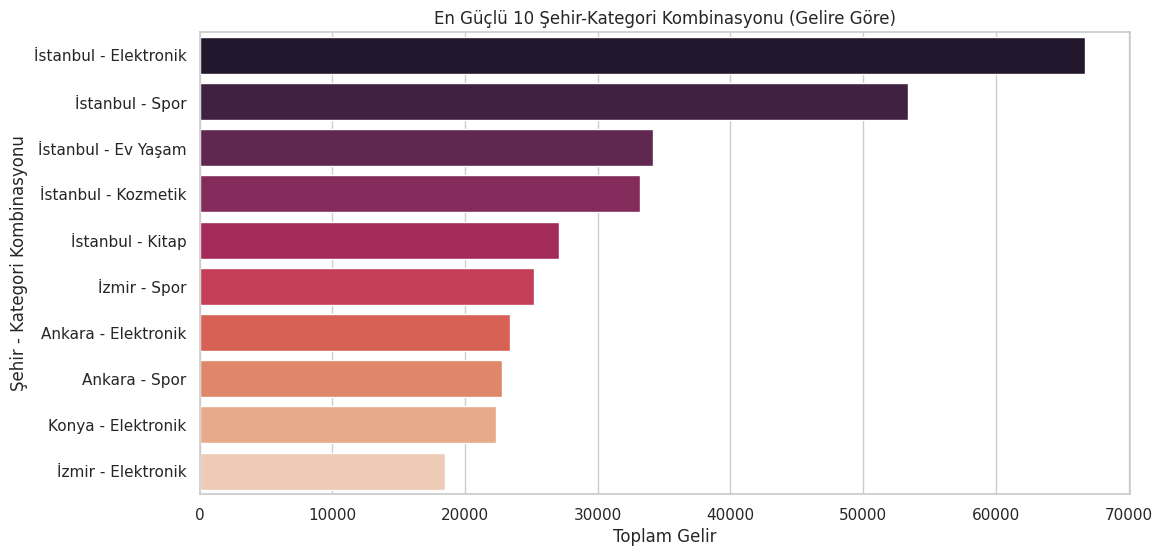


🎯 İŞ YORUMU: En güçlü pazar fırsatı 'İstanbul - Elektronik' kombinasyonunda görülmektedir.
 Pazarlama bütçesi ve bölgesel stok yönetimi bu spesifik ürün-şehir kırılımına ağırlık verecek şekilde optimize edilmelidir.


In [14]:
# Özet Tablo
city_cat_df = df.groupby(['sehir', 'kategori']).agg(
    Siparis_Sayisi=('siparis_id', 'count'),
    Toplam_Gelir=('toplam_tutar', 'sum'),
    Ort_Siparis_Tutari=('toplam_tutar', 'mean'),
    Ort_Musteri_Puani=('musteri_puani', 'mean')
).reset_index()

top10_combos = city_cat_df.sort_values('Toplam_Gelir', ascending=False).head(10).copy()
top10_combos['Sehir_Kategori'] = top10_combos['sehir'] + " - " + top10_combos['kategori']
display(top10_combos)

# Grafik
plt.figure(figsize=(12, 6))
sns.barplot(data=top10_combos, y='Sehir_Kategori', x='Toplam_Gelir', palette='rocket', hue='Sehir_Kategori', legend=False)
plt.title('En Güçlü 10 Şehir-Kategori Kombinasyonu (Gelire Göre)')
plt.xlabel('Toplam Gelir')
plt.ylabel('Şehir - Kategori Kombinasyonu')
plt.show()

# İş Yorumu
best_combo = top10_combos.iloc[0]['Sehir_Kategori']
print(f"\n🎯 İŞ YORUMU: En güçlü pazar fırsatı '{best_combo}' kombinasyonunda görülmektedir.\n Pazarlama bütçesi ve bölgesel stok yönetimi bu spesifik ürün-şehir kırılımına ağırlık verecek şekilde optimize edilmelidir.")